# Mini-Project 2: Uganda Tax Engine

This project models PAYE, payroll deductions, VAT and corporate
income tax using reusable Python classes.

Monetary calculations use Decimal with explicit rounding rules.
Tax schedules and assumptions will be documented alongside their
official sources.

Reusable code will be stored in `src/tax.py`, with automated tests
in `tests/test_tax.py`.

## Tax schedules and sources

### Monthly PAYE

The resident schedule follows URA's notice published on
7 September 2026, effective from 1 July 2026.
It matches the assignment's sample resident PAYE rules.

In the tables below, Y means monthly chargeable employment income
in Uganda shillings.

### Resident individuals

| Monthly chargeable income (UGX) | PAYE calculation |
|---|---|
| Up to 335,000 | Nil |
| Above 335,000 up to 410,000 | 20% × (Y − 335,000) |
| Above 410,000 up to 485,000 | 15,000 + 25% × (Y − 410,000) |
| Above 485,000 up to 10,000,000 | 33,750 + 30% × (Y − 485,000) |
| Above 10,000,000 | 33,750 + 30% × (Y − 485,000) + 10% × (Y − 10,000,000) |

### Non-resident individuals

URA's PAYE rates page gives the following separate schedule.

| Monthly chargeable income (UGX) | PAYE calculation |
|---|---|
| Up to 335,000 | 10% × Y |
| Above 335,000 up to 410,000 | 33,500 + 20% × (Y − 335,000) |
| Above 410,000 up to 10,000,000 | 48,500 + 30% × (Y − 410,000) |
| Above 10,000,000 | 48,500 + 30% × (Y − 410,000) + 10% × (Y − 10,000,000) |

The additional 10% applies only to income exceeding UGX 10 million,
not to the person's entire income.

Sources checked on 10 October 2026:

- URA resident PAYE update:
  https://ura.go.ug/en/changes-to-paye-return-form-following-the-income-tax-amendment-act-2026/
- URA resident and non-resident PAYE schedules:
  https://ura.go.ug/en/domestic-taxes/paye-rates/

## Handling money with Decimal

Binary floating-point numbers cannot represent some decimal
fractions exactly. Small differences can affect comparisons
and rounding in financial calculations.

This project uses Decimal values constructed from strings.
Rounding rules will be stated explicitly in the Money class.
The float calculation below is only a demonstration of the problem;
it will not be used in the tax engine.

In [25]:
# Import Decimal for exact decimal arithmetic.
from decimal import Decimal

# Demonstrate the small representation error in binary floating point.
float_total = 0.1 + 0.2
print("Float total:", float_total)
print("Float equals 0.3:", float_total == 0.3)

# Construct Decimal values from strings to preserve their exact values.
decimal_total = Decimal("0.1") + Decimal("0.2")
print("Decimal total:", decimal_total)
print("Decimal equals 0.3:", decimal_total == Decimal("0.3"))

Float total: 0.30000000000000004
Float equals 0.3: False
Decimal total: 0.3
Decimal equals 0.3: True


In [26]:
# Import tools for locating and reloading our tax module.
import sys
import importlib
from pathlib import Path

# Locate the project root and make its modules available.
project_folder = Path.cwd()
if not (project_folder / "src").is_dir():
    project_folder = project_folder.parent

if str(project_folder) not in sys.path:
    sys.path.insert(0, str(project_folder))

# Import and reload the module to access the Money class.
import src.tax as tax_module
importlib.reload(tax_module)

# Create monetary amounts from exact string inputs.
monthly_salary = tax_module.Money("1500000")
transport_allowance = tax_module.Money("150000")
rounding_example = tax_module.Money("1250.555")

# Display the objects using their __repr__ method.
print("Monthly salary:", monthly_salary)
print("Transport allowance:", transport_allowance)
print("Rounding example:", rounding_example)

Monthly salary: UGX 1,500,000.00
Transport allowance: UGX 150,000.00
Rounding example: UGX 1,250.56


In [27]:
# Import Decimal for an exact multiplication factor.
from decimal import Decimal

# Reload the updated class and recreate its objects.
importlib.reload(tax_module)
monthly_salary = tax_module.Money("1500000")
transport_allowance = tax_module.Money("150000")

# Add the amounts using Money.__add__.
total_pay = monthly_salary + transport_allowance

# Demonstrate multiplication using an illustrative 5% rate.
five_percent = monthly_salary * Decimal("0.05")

# Display the arithmetic and comparison results.
print("Total pay:", total_pay)
print("Five percent of salary:", five_percent)
print("Allowance is less than salary:", transport_allowance < monthly_salary)

Total pay: UGX 1,650,000.00
Five percent of salary: UGX 75,000.00
Allowance is less than salary: True


In [28]:
# Import date to identify the period of the tax calculation.
from datetime import date

# Reload the module to access TaxContext and the current Money class.
importlib.reload(tax_module)

# Group an employee's basic pay, allowances and residency information.
kampala_employee = tax_module.TaxContext(
    income=tax_module.Money("1500000"),
    allowances=tax_module.Money("150000"),
    tax_date=date(2026, 10, 31),
    resident=True
)

# Display the inputs before applying any tax calculation.
print("Basic pay:", kampala_employee.income)
print("Allowances:", kampala_employee.allowances)
print("Deductions:", kampala_employee.deductions)
print("Calculation date:", kampala_employee.tax_date)
print("Resident:", kampala_employee.resident)

Basic pay: UGX 1,500,000.00
Allowances: UGX 150,000.00
Deductions: UGX 0.00
Calculation date: 2026-10-31
Resident: True


In [29]:
# Reload the module to access the PAYE calculator.
importlib.reload(tax_module)

# Recreate the employee context using the reloaded classes.
kampala_employee = tax_module.TaxContext(
    income=tax_module.Money("1500000"),
    allowances=tax_module.Money("150000"),
    tax_date=date(2026, 10, 31),
    resident=True
)

# Calculate PAYE using the resident schedule.
paye_calculator = tax_module.PayeTax()
paye_result = paye_calculator.calculate(kampala_employee)

# Display the chargeable income and calculated tax.
print("Tax:", paye_result.tax_name)
print("Chargeable income:", paye_result.taxable_amount)
print("Monthly PAYE:", paye_result.tax_amount)


Tax: PAYE
Chargeable income: UGX 1,650,000.00
Monthly PAYE: UGX 383,250.00


In [30]:
# Use the same pay and date to compare the two residency schedules.
non_resident_employee = tax_module.TaxContext(
    income=tax_module.Money("1500000"),
    allowances=tax_module.Money("150000"),
    tax_date=date(2026, 10, 31),
    resident=False
)

# Calculate non-resident PAYE using the same calculator object.
non_resident_result = paye_calculator.calculate(non_resident_employee)

# Compare the tax amounts using Decimal arithmetic.
tax_difference = tax_module.Money(
    non_resident_result.tax_amount.amount - paye_result.tax_amount.amount
)

print("Resident PAYE:", paye_result.tax_amount)
print("Non-resident PAYE:", non_resident_result.tax_amount)
print("Additional PAYE for non-resident:", tax_difference)

Resident PAYE: UGX 383,250.00
Non-resident PAYE: UGX 420,500.00
Additional PAYE for non-resident: UGX 37,250.00


## Interpreting the PAYE calculations

The example employee receives basic monthly pay of UGX 1,500,000
and a taxable transport allowance of UGX 150,000. With no permitted
deductions supplied, chargeable income is UGX 1,650,000.

For a resident employee:

PAYE = 33,750 + 30% × (1,650,000 − 485,000)
     = UGX 383,250.

For a non-resident employee:

PAYE = 48,500 + 30% × (1,650,000 − 410,000)
     = UGX 420,500.

The non-resident pays UGX 37,250 more in this example because the
two schedules have different bands and accumulated tax amounts.
This difference is specific to the example, not a fixed amount
for every income level.

Neither calculation attracts the additional 10% charge because
chargeable income is below UGX 10 million.

The calculator supports dates from 1 July 2026 to 30 June 2027.
This is the implementation's supported period, not an assertion
that the legislation expires on that date.

All supplied allowances are treated as taxable in this simplified
model. Deductions must represent permitted adjustments; ordinary
personal expenses must not be entered as PAYE deductions.

Tax is calculated using Decimal and rounded to two decimal places
when the final Money result is created. These results represent
PAYE only; net pay will also account for payroll deductions.

## Payroll assumptions and deduction order

This payroll model assumes the employee is covered by NSSF.
Basic pay and the supplied taxable cash allowances together form
gross monthly pay.

The calculation follows this order:

1. Gross pay = basic pay + taxable allowances.
2. Employee NSSF = 5% of gross pay.
3. Employer NSSF = 10% of gross pay.
4. PAYE chargeable income = gross pay − applicable Local Service Tax.
5. Calculate PAYE using the employee's residency schedule.
6. Net pay = gross pay − employee NSSF − Local Service Tax − PAYE.

Employee NSSF reduces take-home pay but does not reduce the income
used to calculate PAYE. Employer NSSF is an additional employer
cost; it is not deducted from the employee's pay.

Local Service Tax is supplied as a configurable amount for the
particular payroll month. The model does not calculate its annual
assessment, exemptions or instalment schedule. A zero input means
no LST is deducted in that calculation, not that LST is legally
optional whenever an employee is liable.

Only LST will be accepted as a pre-PAYE adjustment by this simplified
payroll pipeline. Other deductions and non-cash benefits are outside
its scope.

Sources checked on 10 October 2026:
- NSSF contribution rates:
  https://www.nssfug.org/about-us/membership/
- URA employment income and relief:
  https://ura.go.ug/en/employment-income/

In [31]:
# Reload the module and recreate objects using the updated classes.
importlib.reload(tax_module)

kampala_employee = tax_module.TaxContext(
    income=tax_module.Money("1500000"),
    allowances=tax_module.Money("150000"),
    tax_date=date(2026, 10, 31),
    resident=True
)

# Combine the payroll calculation with our PAYE calculator.
payroll = tax_module.Payroll(tax_module.PayeTax())

# Use an illustrative LST deduction for this particular month.
payroll_result = payroll.calculate(
    kampala_employee,
    local_service_tax=tax_module.Money("25000")
)

# Display the employee deductions, take-home pay and employer cost.
print("Gross pay:", payroll_result.gross_pay)
print("Employee NSSF:", payroll_result.employee_nssf)
print("Employer NSSF:", payroll_result.employer_nssf)
print("Local Service Tax:", payroll_result.local_service_tax)
print("PAYE chargeable income:", payroll_result.chargeable_income)
print("PAYE:", payroll_result.paye)
print("Net pay:", payroll_result.net_pay)
print("Employer cost:", payroll_result.employer_cost)

Gross pay: UGX 1,650,000.00
Employee NSSF: UGX 82,500.00
Employer NSSF: UGX 165,000.00
Local Service Tax: UGX 25,000.00
PAYE chargeable income: UGX 1,625,000.00
PAYE: UGX 375,750.00
Net pay: UGX 1,166,750.00
Employer cost: UGX 1,815,000.00


### Interpreting the payroll result

Gross monthly pay is UGX 1,650,000. Employee NSSF is 5% of this
amount, giving UGX 82,500. Employer NSSF is 10%, giving UGX 165,000.

The illustrative LST deduction of UGX 25,000 reduces PAYE
chargeable income to UGX 1,625,000. Employee NSSF does not
reduce this chargeable income.

Resident PAYE is:

33,750 + 30% × (1,625,000 − 485,000) = UGX 375,750.

Net pay is:

1,650,000 − 82,500 − 25,000 − 375,750 = UGX 1,166,750.

Employer cost is gross pay plus employer NSSF:

1,650,000 + 165,000 = UGX 1,815,000.

Compared with the earlier example without LST, PAYE falls by
UGX 7,500 because the UGX 25,000 adjustment falls within the
30% marginal band. LST still reduces take-home pay: the PAYE
saving offsets only part of the deduction.

Payroll uses composition by holding a PayeTax calculator.
This keeps payroll coordination separate from the progressive
tax rules and avoids duplicating the PAYE calculation.

## VAT rules and assumptions

This module models a VAT-registered business using invoices whose
amounts exclude VAT.

It distinguishes three supply categories:

- Standard-rated: VAT is calculated at 18%.
- Zero-rated: the supply is taxable, but VAT is calculated at 0%.
- Exempt: no VAT is charged, and input VAT directly attributable
  to making exempt supplies is not recoverable.

Output VAT is the VAT charged on sales. Input VAT is VAT charged
on purchases. Only eligible input VAT is deducted when calculating
the net VAT balance.

Net VAT balance = output VAT − recoverable input VAT.

A positive balance represents VAT payable. A negative balance
represents an excess input VAT credit, not an automatic cash refund.

The model records purchase eligibility explicitly. A standard-rated
purchase is not automatically eligible for an input credit: its use
and supporting documentation matter. Purchases used exclusively
for exempt supplies must be marked ineligible.

Zero-rated and exempt purchases themselves carry no VAT to recover.
However, eligible standard-rated purchases used to make zero-rated
sales can generate recoverable input VAT.

This simplified model assumes invoice classifications and eligibility
have already been checked. It does not determine product classifications,
verify EFRIS documents or calculate mixed-use input tax apportionment.

Sources checked on 11 October 2026:
- URA VAT guidance:
  https://ura.go.ug/en/value-added-tax-vat/
- URA Taxation Handbook FY2023/24, input tax attribution guidance:
  https://ura.go.ug/wp-content/uploads/2024/06/Taxation-handbook-FY2023-24.pdf

In [32]:
# Reload the module to access the Invoice class.
importlib.reload(tax_module)

# Create illustrative invoices with amounts excluding VAT.
jinja_traders_invoices = [
    tax_module.Invoice(
        reference="SALE-001",
        amount=tax_module.Money("1000000"),
        transaction="sale",
        category="standard"
    ),
    tax_module.Invoice(
        reference="SALE-002",
        amount=tax_module.Money("500000"),
        transaction="sale",
        category="zero"
    ),
    tax_module.Invoice(
        reference="SALE-003",
        amount=tax_module.Money("300000"),
        transaction="sale",
        category="exempt"
    ),
    tax_module.Invoice(
        reference="PURCHASE-001",
        amount=tax_module.Money("400000"),
        transaction="purchase",
        category="standard",
        input_vat_eligible=True
    ),
    tax_module.Invoice(
        reference="PURCHASE-002",
        amount=tax_module.Money("100000"),
        transaction="purchase",
        category="standard",
        input_vat_eligible=False
    )
]

# Display VAT charged separately from eligibility for an input credit.
for invoice in jinja_traders_invoices:
    print(
        f"{invoice.reference}: {invoice.transaction}, "
        f"{invoice.category}, VAT = {invoice.vat_amount()}, "
        f"input credit eligible = {invoice.input_vat_eligible}"
    )

SALE-001: sale, standard, VAT = UGX 180,000.00, input credit eligible = False
SALE-002: sale, zero, VAT = UGX 0.00, input credit eligible = False
SALE-003: sale, exempt, VAT = UGX 0.00, input credit eligible = False
PURCHASE-001: purchase, standard, VAT = UGX 72,000.00, input credit eligible = True
PURCHASE-002: purchase, standard, VAT = UGX 18,000.00, input credit eligible = False


In [33]:
# Supply the invoice list for the October VAT calculation.
jinja_vat_context = tax_module.TaxContext(
    income=tax_module.Money("0"),
    tax_date=date(2026, 10, 31),
    invoices=jinja_traders_invoices
)

# Calculate VAT using the classified sales and purchases.
vat_calculator = tax_module.VatTax()
vat_result = vat_calculator.calculate(jinja_vat_context)

# Display charged VAT, recoverable input VAT and the resulting balance.
print("Taxable sales excluding VAT:", vat_result.taxable_amount)
print("Output VAT:", vat_result.output_vat)
print("Input VAT charged:", vat_result.input_vat_charged)
print("Recoverable input VAT:", vat_result.recoverable_input_vat)
print("Net VAT balance:", vat_result.tax_amount)
print("VAT payable:", vat_result.vat_payable)
print("Excess input credit:", vat_result.credit_balance)

Taxable sales excluding VAT: UGX 1,500,000.00
Output VAT: UGX 180,000.00
Input VAT charged: UGX 90,000.00
Recoverable input VAT: UGX 72,000.00
Net VAT balance: UGX 108,000.00
VAT payable: UGX 108,000.00
Excess input credit: UGX 0.00


### Interpreting the VAT result

Jinja Traders has UGX 1,000,000 in standard-rated sales and
UGX 500,000 in zero-rated sales. Both form part of taxable turnover,
giving UGX 1,500,000. The UGX 300,000 in exempt sales is excluded
from taxable turnover.

Only the standard-rated sale generates output VAT:

1,000,000 × 18% = UGX 180,000.

The two standard-rated purchases carry VAT of UGX 72,000 and
UGX 18,000, giving total input VAT charged of UGX 90,000.

Only UGX 72,000 is recoverable. The other purchase is assumed
to relate exclusively to exempt supplies, so its UGX 18,000
cannot reduce the VAT payable.

Net VAT payable is therefore:

180,000 − 72,000 = UGX 108,000.

Deducting all UGX 90,000 would incorrectly reduce the payment
to UGX 90,000, understating VAT payable by UGX 18,000.

Zero-rated and exempt sales both generate no output VAT here,
but their input-credit treatment differs. The model preserves
their separate classifications rather than treating them as
the same category.

VAT is rounded to two decimal places for each invoice before
the amounts are totalled. An excess recoverable input balance
would be shown separately as a credit, not an automatic refund.

## Corporate income tax

This module models a resident company subject to the standard
corporate income tax rate of 30%.

For this simplified calculation:

Chargeable income = revenue − allowable deductions.

Tax = 30% × positive chargeable income.

If allowable deductions exceed revenue, the model reports zero
current tax. It does not calculate loss carry-forwards or refunds.

The inputs represent annual amounts for the same accounting period.
In TaxContext, income represents revenue and deductions represents
expenses already assessed as allowable. Allowances and invoices
are not used in this calculation.

Accounting expenses are not automatically allowable tax deductions.
The caller must supply the allowable amount after making the
necessary tax adjustments.

This model excludes special rates, exemptions, tax incentives,
presumptive taxation, withholding credits and provisional payments.
The resulting tax is therefore the calculated annual liability
before those payments or credits, not necessarily the outstanding
amount payable to URA.

The example will use an annual accounting period ending
30 June 2027, within the implementation's supported date range.

Sources checked on 11 October 2026:
- URA corporation tax:
  https://ura.go.ug/en/corporation-tax/
- URA business income:
  https://ura.go.ug/en/business-income/

In [34]:
# Reload the module to access the corporate income tax calculator.
importlib.reload(tax_module)

# Supply annual revenue and allowable deductions for an example company.
jinja_company = tax_module.TaxContext(
    income=tax_module.Money("250000000"),
    deductions=tax_module.Money("175000000"),
    tax_date=date(2027, 6, 30),
    resident=True
)

# Calculate the company's annual tax before payments and credits.
corporate_calculator = tax_module.CorporateTax()
corporate_result = corporate_calculator.calculate(jinja_company)

# Display the calculation inputs and result.
print("Annual revenue:", jinja_company.income)
print("Allowable deductions:", jinja_company.deductions)
print("Chargeable income:", corporate_result.taxable_amount)
print("Corporate income tax:", corporate_result.tax_amount)

Annual revenue: UGX 250,000,000.00
Allowable deductions: UGX 175,000,000.00
Chargeable income: UGX 75,000,000.00
Corporate income tax: UGX 22,500,000.00


### Interpreting the corporate tax result

The example company has annual revenue of UGX 250,000,000 and
allowable deductions of UGX 175,000,000.

Chargeable income is UGX 75,000,000, producing corporate income
tax of UGX 22,500,000 at 30%.

This is the annual liability before provisional payments or tax
credits. It is not necessarily the amount still outstanding.

A separate automated test confirms that deductions exceeding
revenue produce zero current tax. Loss carry-forwards are outside
this simplified model.

## Extension B: Comparing two payroll scenarios

The TaxPlanner will compare two monthly salary offers for the
same employee, using the same calculation date and residency.

It will report differences in gross pay, PAYE, employee NSSF,
net pay and employer cost. Local Service Tax will be supplied
explicitly for each scenario.

The comparison will reuse the Payroll calculator rather than
duplicate its deduction rules. It compares the financial outcomes
of the supplied offers; it does not determine whether their
allowances or deductions qualify for a particular legal treatment.

In [35]:
# Reload the module to access the planner and recreate current class objects.
importlib.reload(tax_module)

# Define the employee's current monthly salary offer.
current_offer = tax_module.TaxContext(
    income=tax_module.Money("1500000"),
    allowances=tax_module.Money("150000"),
    tax_date=date(2026, 10, 31),
    resident=True
)

# Increase basic pay while keeping the allowance unchanged.
proposed_offer = tax_module.TaxContext(
    income=tax_module.Money("1800000"),
    allowances=tax_module.Money("150000"),
    tax_date=date(2026, 10, 31),
    resident=True
)

# Build the planner using the existing payroll and PAYE calculators.
planner = tax_module.TaxPlanner(
    tax_module.Payroll(tax_module.PayeTax())
)

# Keep the illustrative LST amount unchanged for this comparison.
offer_comparison = planner.compare(
    current=current_offer,
    proposed=proposed_offer,
    current_lst=tax_module.Money("25000"),
    proposed_lst=tax_module.Money("25000")
)

# Display the change from the current offer to the proposed offer.
print("Current net pay:", offer_comparison.current.net_pay)
print("Proposed net pay:", offer_comparison.proposed.net_pay)
print("Gross pay increase:", offer_comparison.gross_pay_change)
print("PAYE increase:", offer_comparison.paye_change)
print("Employee NSSF increase:", offer_comparison.employee_nssf_change)
print("Net pay increase:", offer_comparison.net_pay_change)
print("Employer cost increase:", offer_comparison.employer_cost_change)

Current net pay: UGX 1,166,750.00
Proposed net pay: UGX 1,361,750.00
Gross pay increase: UGX 300,000.00
PAYE increase: UGX 90,000.00
Employee NSSF increase: UGX 15,000.00
Net pay increase: UGX 195,000.00
Employer cost increase: UGX 330,000.00


### Interpreting the salary comparison

The proposed offer increases monthly basic pay by UGX 300,000,
while the taxable allowance and illustrative LST deduction remain
unchanged.

PAYE increases by UGX 90,000 because the additional chargeable
income falls entirely within the 30% marginal band. Employee NSSF
increases by UGX 15,000, which is 5% of the additional gross pay.

The employee's net pay therefore increases by:

300,000 − 90,000 − 15,000 = UGX 195,000.

Net pay rises from UGX 1,166,750 to UGX 1,361,750.
The employee retains 65% of this particular gross pay increase.

The employer's monthly cost rises by UGX 330,000: the additional
UGX 300,000 gross pay plus UGX 30,000 in employer NSSF.

These percentages describe this example. A different income level,
a change in LST or crossing a PAYE band could change the outcome.

TaxPlanner uses the same Payroll calculator for both scenarios.
This keeps the comparison consistent with the main payroll
calculation and avoids maintaining a second set of tax rules.

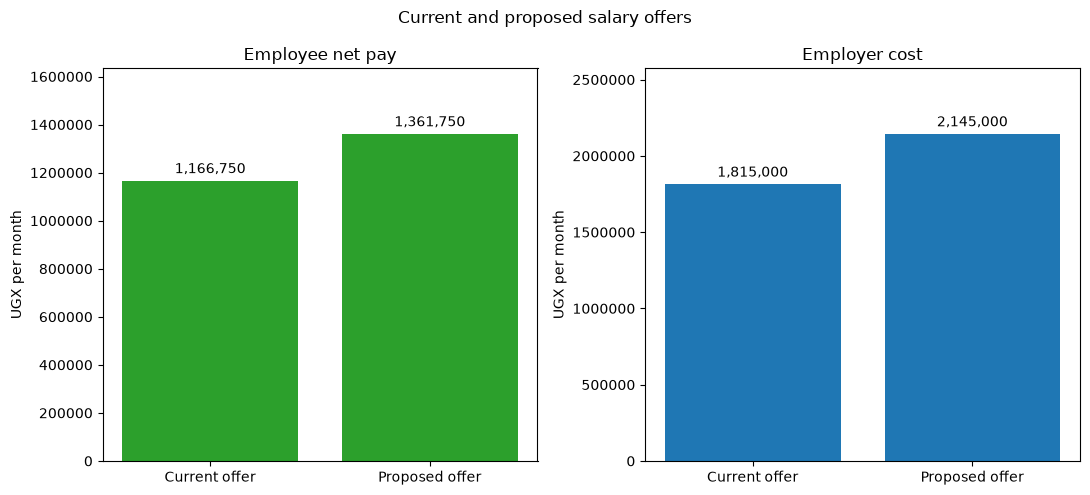

In [36]:
# Import plotting tools for comparing the two payroll scenarios.
import matplotlib.pyplot as plt

# Use completed Decimal calculations; convert only for chart display.
labels = ["Current offer", "Proposed offer"]
net_pay_values = [
    float(offer_comparison.current.net_pay.amount),
    float(offer_comparison.proposed.net_pay.amount)
]
employer_cost_values = [
    float(offer_comparison.current.employer_cost.amount),
    float(offer_comparison.proposed.employer_cost.amount)
]

# Draw separate panels for employee net pay and employer cost.
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for axis, values, title, colour in [
    (axes[0], net_pay_values, "Employee net pay", "tab:green"),
    (axes[1], employer_cost_values, "Employer cost", "tab:blue")
]:
    bars = axis.bar(labels, values, color=colour)
    axis.set_title(title)
    axis.set_ylabel("UGX per month")
    axis.set_ylim(0, max(values) * 1.2)
    axis.ticklabel_format(style="plain", axis="y")
    axis.bar_label(bars, labels=[f"{value:,.0f}" for value in values], padding=3)

# Label the comparison and display the chart.
fig.suptitle("Current and proposed salary offers")
fig.tight_layout()
plt.show()

## Discussion: inheritance and composition

Tax is an abstract base class defining the common
calculate(ctx) interface. PayeTax, VatTax and CorporateTax inherit
from it because each represents a tax calculation. Their rules
differ, but each accepts a TaxContext and returns a TaxResult
or a specialised result derived from it.

VatResult extends TaxResult because a VAT result needs the common
tax fields plus details such as output VAT, recoverable input VAT
and an excess credit balance.

The exception hierarchy also uses inheritance. InvalidIncomeError
and NoScheduleForDateError are specific forms of TaxError.
This allows callers to handle a particular failure or catch the
broader group of tax-engine errors.

Payroll does not inherit from Tax because it coordinates several
deductions and employer costs rather than representing one tax.
It contains a PayeTax calculator instead. TaxPlanner similarly
contains a Payroll object and reuses it for both scenarios.
These relationships demonstrate composition.

Money keeps decimal arithmetic, rounding and monetary display
together. Its operator methods support addition, multiplication
and comparison without repeating those operations throughout
the application. Invoice holds transaction details and calculates
the VAT charged on an individual invoice.

TaxContext and the result dataclasses group related information.
Using one context simplifies the common interface, although it
also creates fields that are irrelevant to some calculators.
The VAT and corporate calculators reject incompatible populated
fields. Separate specialised contexts could improve this design
if the project grew.

The charts convert completed Decimal amounts to float only for
display. These plotting values are never used to calculate tax,
deductions, net pay or employer cost.

In [ ]:
# Demonstrate rejection of a float in monetary calculations.
# Deliberately pass a float to demonstrate its rejection.
try:
    tax_module.Money(0.1)  # pyright: ignore[reportArgumentType]
except tax_module.TaxError as error:
    print("Float rejected:", error)

# Demonstrate rejection of negative income.
try:
    tax_module.TaxContext(
        income=tax_module.Money("-100"),
        tax_date=date(2026, 10, 31)
    )
except tax_module.InvalidIncomeError as error:
    print("Negative income rejected:", error)

# Demonstrate rejection of a date outside the implemented PAYE schedule.
try:
    earlier_payroll = tax_module.TaxContext(
        income=tax_module.Money("1500000"),
        tax_date=date(2026, 6, 30)
    )
    tax_module.PayeTax().calculate(earlier_payroll)
except tax_module.NoScheduleForDateError as error:
    print("Unsupported date:", error)

Float rejected: Money requires a string, integer or Decimal.
Negative income rejected: income cannot be negative.
Unsupported date: PAYE is supported from 1 July 2026 to 30 June 2027.


## Testing and limitations

The tax test suite passed 18 cases. These cover resident PAYE
boundaries, property-based checks for both residency schedules,
payroll reconciliation, VAT payable and credit balances, corporate
profit and loss examples, salary comparisons and selected invalid
inputs.

Hypothesis generates incomes from UGX 0 to UGX 100,000,000 with
two decimal places. It checks that PAYE is non-negative, does not
exceed income and does not decrease as income increases when
residency and other inputs remain unchanged.

The property tests use derandomize=True for reproducible generation
with an unchanged test and environment. Passing these examples
does not prove correctness for every possible input.

Money rejects float inputs and rounds to two decimal places using
ROUND_HALF_UP. This is an explicit project convention, not a claim
about the rounding required in every URA return. The deliberate
float-rejection examples use a targeted type-checker suppression
because their purpose is to test invalid input.

The supported calculation period is 1 July 2026 to 30 June 2027.
Unsupported dates raise NoScheduleForDateError rather than silently
using a potentially inappropriate schedule.

The model assumes taxable allowances, allowable corporate
deductions and VAT classifications have already been identified
correctly. It does not assess LST annually, determine NSSF
eligibility, verify EFRIS documents or apportion mixed-use VAT.

Corporate tax excludes special regimes, loss carry-forwards and
payments already made. VAT credit balances do not represent
automatic refunds. The planner compares only the supplied payroll
scenarios under matching dates and residency.